In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv("../data/raw/train_FD001.txt", sep=r"\s+", header=None, names=cols)
print(train.shape)
train.head()

(20631, 26)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [2]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
op1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
s2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


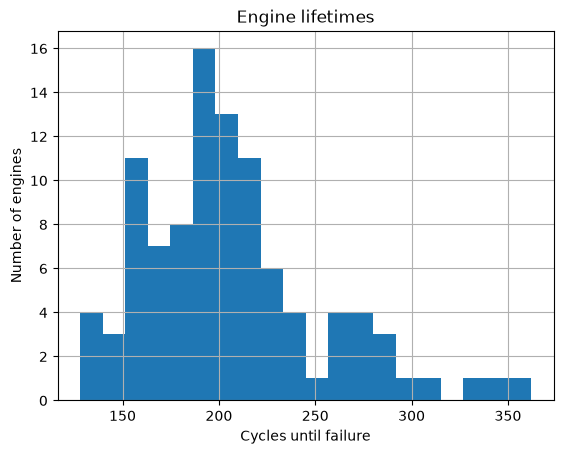

In [3]:
lifetimes = train.groupby("unit")["cycle"].max()
print(lifetimes.describe())
lifetimes.hist(bins=20)
plt.xlabel("Cycles until failure")
plt.ylabel("Number of engines")
plt.title("Engine lifetimes")
plt.show()

In [4]:
train.std().sort_values().head(10)

s19    0.000000e+00
op3    0.000000e+00
s1     0.000000e+00
s18    0.000000e+00
s10    0.000000e+00
s16    3.469531e-18
s5     5.329200e-15
op2    2.930621e-04
s6     1.388985e-03
op1    2.187313e-03
dtype: float64

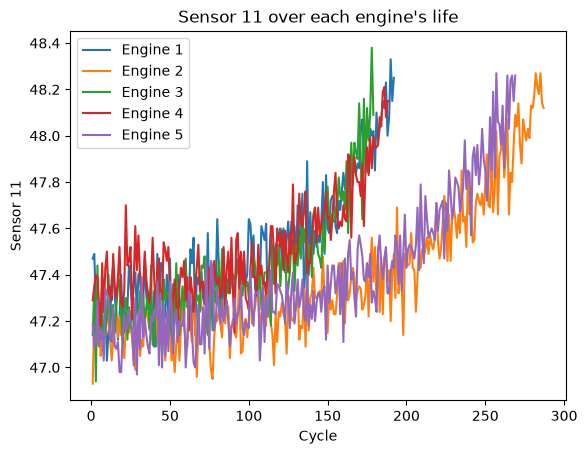

In [5]:
for unit in [1, 2, 3, 4, 5]:
    engine = train[train["unit"] == unit]
    plt.plot(engine["cycle"], engine["s11"], label=f"Engine {unit}")
plt.xlabel("Cycle")
plt.ylabel("Sensor 11")
plt.title("Sensor 11 over each engine's life")
plt.legend()
plt.savefig("../reports/figures/sensor_trends.png")
plt.show()

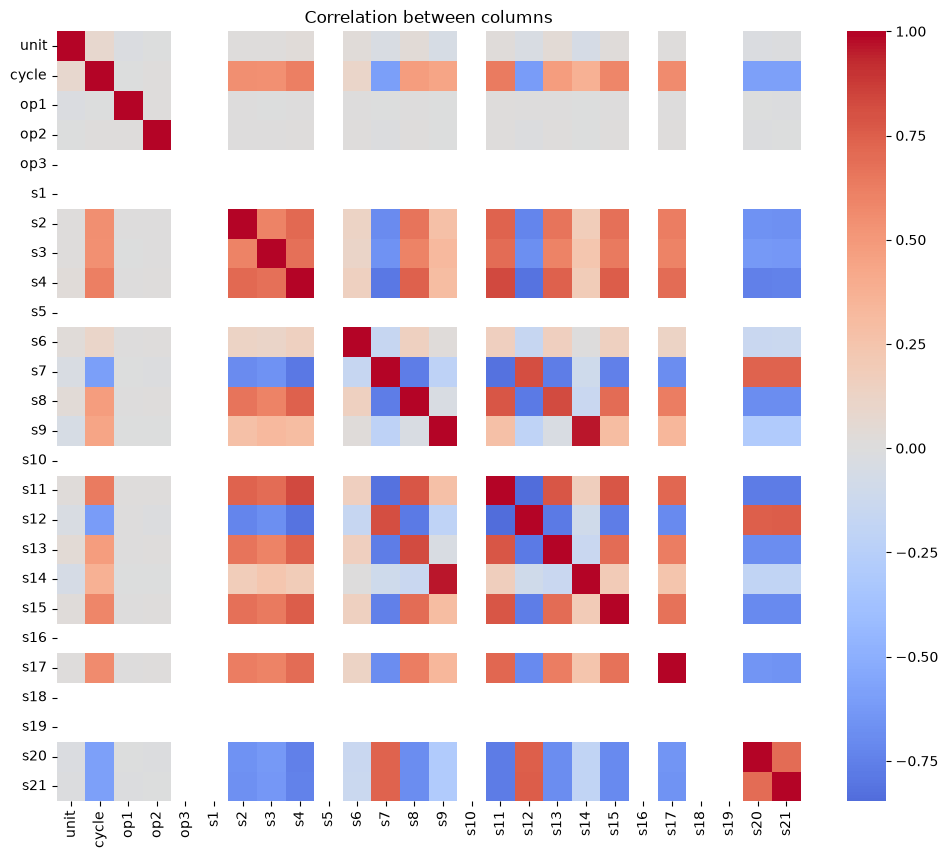

In [6]:
plt.figure(figsize=(12, 10))
sns.heatmap(train.corr(), cmap="coolwarm", center=0)
plt.title("Correlation between columns")
plt.show()